In [191]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [192]:
df = pd.read_csv('dataset.csv')

In [193]:
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [194]:
df.isna().sum()

Age                           0
Education_Level               0
Years_of_Experience           0
Industry                      0
Job_Role                      0
Company_Size                  0
Job_Level                     0
Routine_Task_Percentage       0
Creativity_Requirement        0
Human_Interaction_Level       0
AI_Adoption_Level             0
Number_of_AI_Tools_Used       0
AI_Usage_Hours_Per_Week       0
Tasks_Automated_Percentage    0
AI_Training_Hours             0
Layoff_Risk                   0
dtype: int64

In [195]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Age                         20000 non-null  int64 
 1   Education_Level             20000 non-null  object
 2   Years_of_Experience         20000 non-null  int64 
 3   Industry                    20000 non-null  object
 4   Job_Role                    20000 non-null  object
 5   Company_Size                20000 non-null  object
 6   Job_Level                   20000 non-null  object
 7   Routine_Task_Percentage     20000 non-null  int64 
 8   Creativity_Requirement      20000 non-null  int64 
 9   Human_Interaction_Level     20000 non-null  int64 
 10  AI_Adoption_Level           20000 non-null  object
 11  Number_of_AI_Tools_Used     20000 non-null  int64 
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64 
 13  Tasks_Automated_Percentage  20000 non-null  in

# Исследование распределения качествeныых переменных

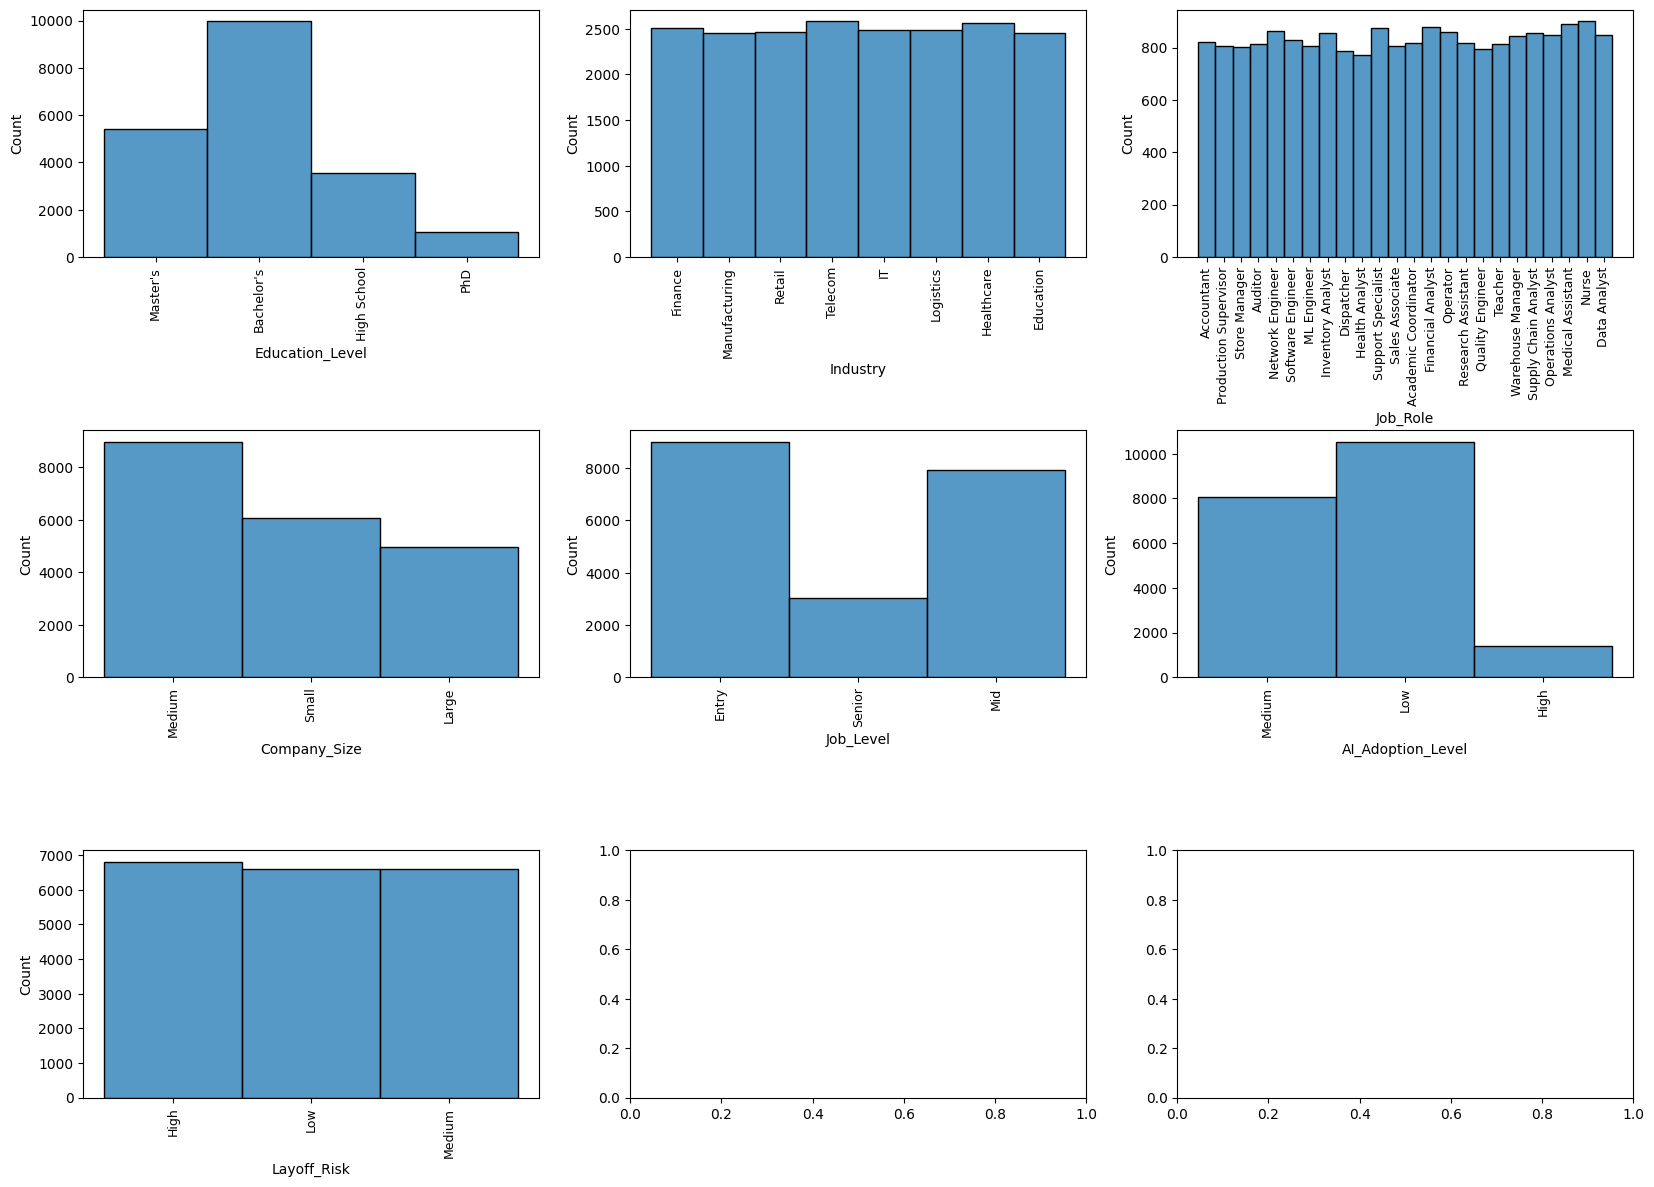

In [196]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 16))
i, j = 0, 0
for col in df.select_dtypes('object').columns:
    if j > 2:
        j = 0 
        i += 1
    sns.histplot(df, x=col, ax=axes[i,j])
    axes[i,j].tick_params(axis='x', rotation=90, labelsize=9)
    j+=1
plt.subplots_adjust(hspace=0.7, bottom=0.2)

In [197]:
for col in df.select_dtypes('object').columns:
    chi, p_value = stats.chisquare(f_obs=df[col].value_counts())
    print(f'Столбец {col}')
    if p_value < 0.05:
        print(f'p_value: {p_value}, отвергаем H0 о равновероятности распредления классов и принимаем H1')
    else:
        print(f'p_value: {p_value}, классы равновероятны')
    print()

Столбец Education_Level
p_value: 0.0, отвергаем H0 о равновероятности распредления классов и принимаем H1

Столбец Industry
p_value: 0.4679114893383086, классы равновероятны

Столбец Job_Role
p_value: 0.10790028551442922, классы равновероятны

Столбец Company_Size
p_value: 3.770681869492396e-278, отвергаем H0 о равновероятности распредления классов и принимаем H1

Столбец Job_Level
p_value: 0.0, отвергаем H0 о равновероятности распредления классов и принимаем H1

Столбец AI_Adoption_Level
p_value: 0.0, отвергаем H0 о равновероятности распредления классов и принимаем H1

Столбец Layoff_Risk
p_value: 0.14792498379028757, классы равновероятны



# Исследование распределения количественных переменных

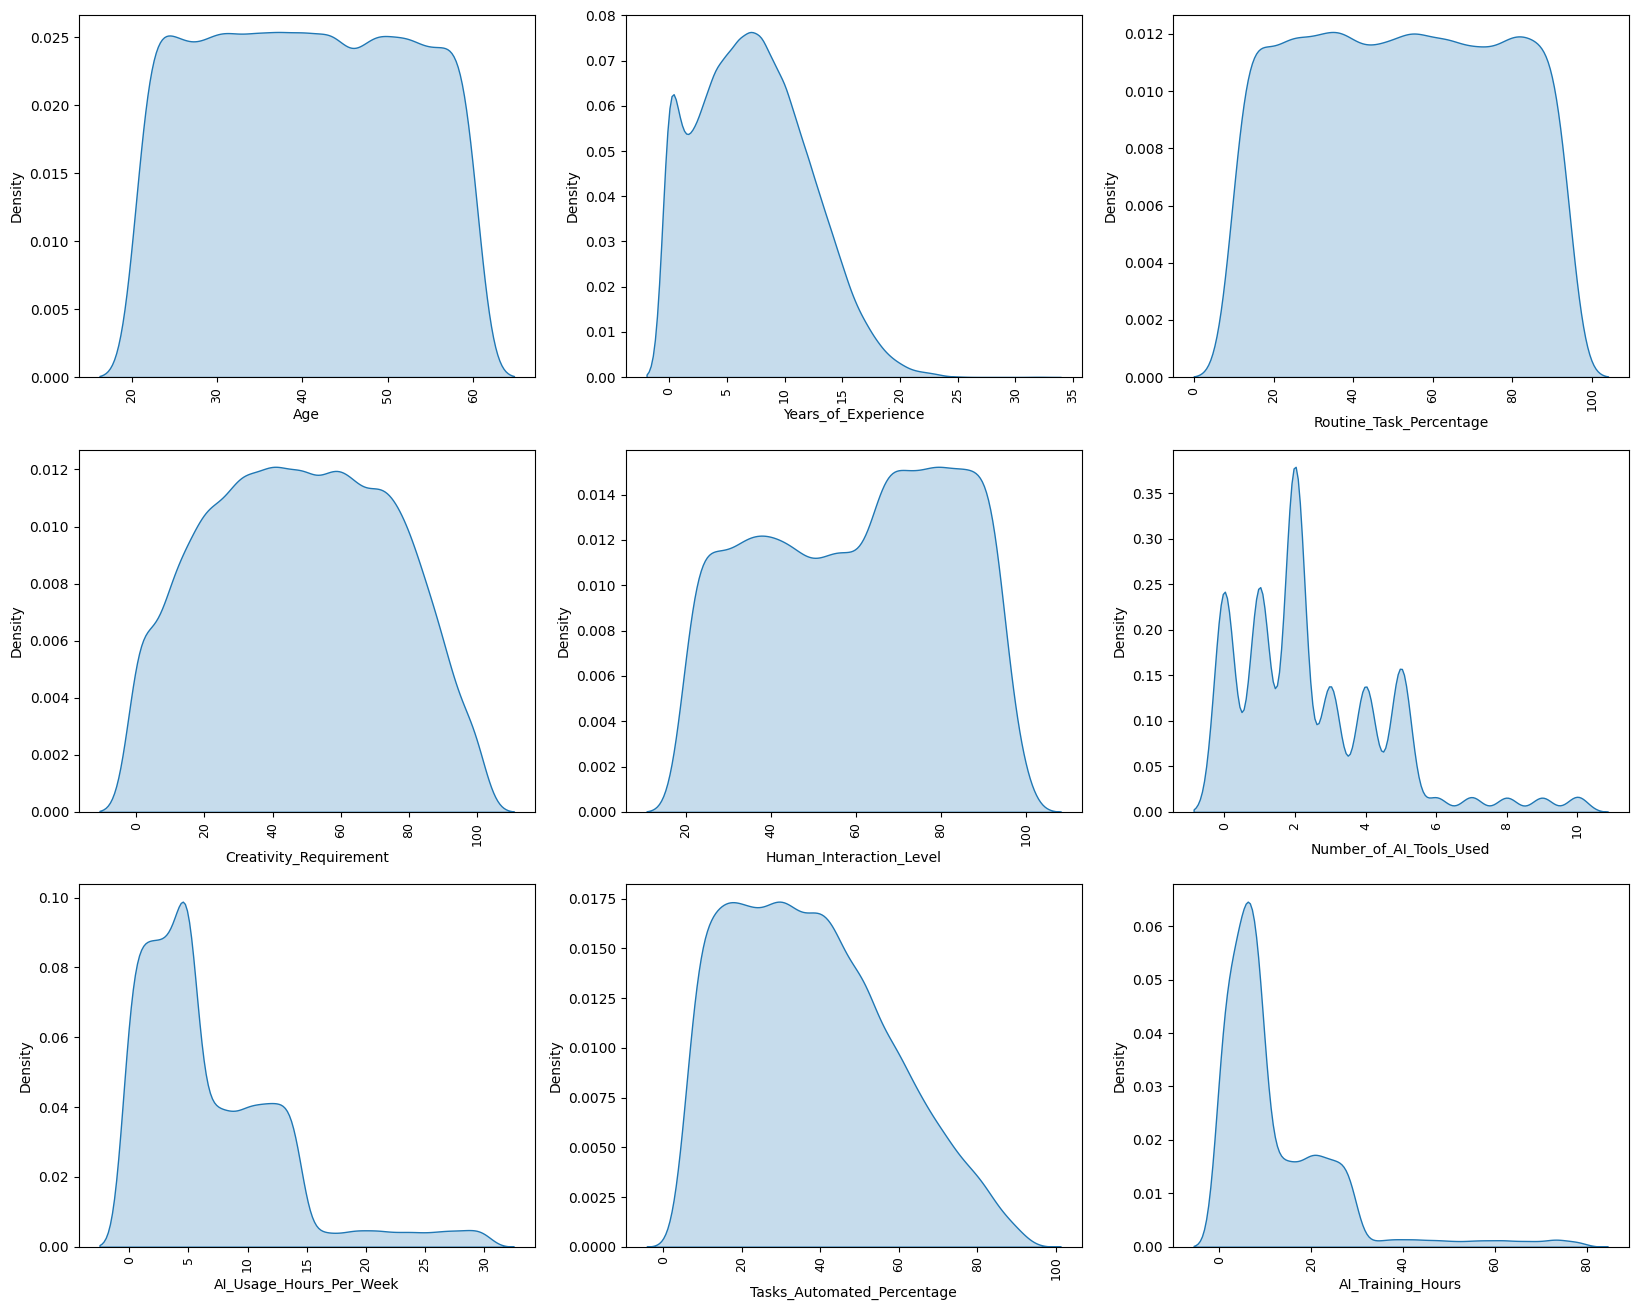

In [198]:

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 16))
i, j = 0, 0
for col in df.select_dtypes(['int64', 'float']).columns:
    if j > 2:
        j = 0 
        i += 1
    sns.kdeplot(df, x=col, ax=axes[i,j], fill=True)
    axes[i,j].tick_params(axis='x', rotation=90, labelsize=9)
    j+=1


In [199]:
for col in df.select_dtypes(['int64', 'float']).columns:
    if 'Percentage' in col.split('_') or 'Level' in col.split('_'):
        setting_of_diap = (0,100)
        res = stats.kstest(df[col], 'uniform', args=setting_of_diap)
        print(f'Столбец {col}')
        if res.pvalue < 0.05:
            print(f'p_value: {res.pvalue}, отвергаем H0 о равномерном распределении перeменной принимаем H1')
        else:
            print(f'p_value: {res.pvalue}, классы равновероятны')
        print()
    else:
        res = stats.kstest(df[col], 'uniform')
        print(f'Столбец {col}')
        if res.pvalue < 0.05:
            print(f'p_value: {res.pvalue}, отвергаем H0 о равномерном распределении перeменной принимаем H1')
        else:
            print(f'p_value: {res.pvalue}, классы равновероятны')
        print()
        

Столбец Age
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец Years_of_Experience
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец Routine_Task_Percentage
p_value: 1.4723820041654693e-174, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец Creativity_Requirement
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец Human_Interaction_Level
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец Number_of_AI_Tools_Used
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец AI_Usage_Hours_Per_Week
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец Tasks_Automated_Percentage
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1

Столбец AI_Training_Hours
p_value: 0.0, отвергаем H0 о равномерном распределении перeменной принимаем H1



# Препроцессинг данных
Стандартизация количествнных признаков, One-hot-encoding качественных и OrdinalEncoding дискретных

In [200]:
from sklearn.preprocessing import StandardScaler

In [201]:
scaler = StandardScaler()

In [202]:
df[df.select_dtypes(['int64', 'float']).columns] = scaler.fit_transform(df.select_dtypes(['int64', 'float']))
df

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,1.617077,Master's,-0.268087,Finance,Accountant,Medium,Entry,1.314165,-1.026317,1.524436,Medium,1.210837,0.037141,0.138590,0.987182,High
1,0.315676,Master's,1.426653,Manufacturing,Production Supervisor,Small,Entry,-0.895581,1.387492,0.356802,Low,-0.219483,-0.784387,-1.161760,-0.267216,Low
2,-0.378404,Bachelor's,-0.056244,Retail,Store Manager,Medium,Senior,-1.632163,1.464121,0.491529,Low,-1.173029,-0.948693,-1.561868,-0.709945,Low
3,-1.159244,Bachelor's,-0.268087,Finance,Auditor,Large,Entry,1.559692,-1.141260,-1.753922,Medium,0.257291,0.530058,1.488953,0.987182,High
4,0.749476,High School,1.002968,Finance,Auditor,Small,Entry,-0.118078,0.161430,0.536438,Medium,1.210837,1.022975,-0.561599,0.470665,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,1.356797,Bachelor's,0.579283,Retail,Sales Associate,Small,Entry,-0.936503,0.544574,-0.721014,Low,-1.173029,-0.455776,-1.061733,-0.931310,Medium
19996,0.228916,Bachelor's,0.367441,Manufacturing,Production Supervisor,Medium,Entry,1.436928,-1.064631,-1.798831,High,3.117929,2.666032,1.989088,4.012497,High
19997,-1.072484,High School,-0.056244,Telecom,Support Specialist,Medium,Entry,1.600613,-1.754291,-0.496469,Medium,-0.219483,1.187281,0.888792,-0.193428,High
19998,0.489196,Bachelor's,-0.903614,Manufacturing,Quality Engineer,Medium,Senior,0.986795,-0.298343,1.299891,Medium,0.257291,1.022975,1.438940,-0.562369,Medium


In [203]:
from sklearn.preprocessing import OrdinalEncoder

In [204]:
columns_for_hot = ['Industry', 'Job_Role']
columns_for_label = df.select_dtypes('object').drop(columns_for_hot, axis=1).columns

In [205]:
for column in columns_for_label:
    print(df[column].value_counts().index)

Index(['Bachelor's', 'Master's', 'High School', 'PhD'], dtype='object', name='Education_Level')
Index(['Medium', 'Small', 'Large'], dtype='object', name='Company_Size')
Index(['Entry', 'Mid', 'Senior'], dtype='object', name='Job_Level')
Index(['Low', 'Medium', 'High'], dtype='object', name='AI_Adoption_Level')
Index(['High', 'Low', 'Medium'], dtype='object', name='Layoff_Risk')


In [206]:


ordinal_encoder = OrdinalEncoder(
    categories=[
        ['High School', "Bachelor's", "Master's", 'PhD'],  # Education_Level
        ['Small', 'Medium', 'Large'],                       # Company_Size
        ['Entry', 'Mid', 'Senior'],                         # Job_Level
        ['Low', 'Medium', 'High'],                          # AI_Adoption_Level
        ['Low', 'Medium', 'High']                           # Layoff_Risk
    ]
)

columns_for_ordinal = ['Education_Level', 'Company_Size', 'Job_Level', 
                       'AI_Adoption_Level', 'Layoff_Risk']

df[columns_for_ordinal] = ordinal_encoder.fit_transform(df[columns_for_ordinal])

In [207]:
df = pd.get_dummies(df, columns=columns_for_hot, drop_first=True, dtype=int)
df

,Age,Education_Level,Years_of_Experience,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,...,Job_Role_Production Supervisor,Job_Role_Quality Engineer,Job_Role_Research Assistant,Job_Role_Sales Associate,Job_Role_Software Engineer,Job_Role_Store Manager,Job_Role_Supply Chain Analyst,Job_Role_Support Specialist,Job_Role_Teacher,Job_Role_Warehouse Manager
0,1.617077,2.0,-0.268087,1.0,0.0,1.314165,-1.026317,1.524436,1.0,1.210837,...,0,0,0,0,0,0,0,0,0,0
1,0.315676,2.0,1.426653,0.0,0.0,-0.895581,1.387492,0.356802,0.0,-0.219483,...,1,0,0,0,0,0,0,0,0,0
2,-0.378404,1.0,-0.056244,1.0,2.0,-1.632163,1.464121,0.491529,0.0,-1.173029,...,0,0,0,0,0,1,0,0,0,0
3,-1.159244,1.0,-0.268087,2.0,0.0,1.559692,-1.141260,-1.753922,1.0,0.257291,...,0,0,0,0,0,0,0,0,0,0
4,0.749476,0.0,1.002968,0.0,0.0,-0.118078,0.161430,0.536438,1.0,1.210837,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,1.356797,1.0,0.579283,0.0,0.0,-0.936503,0.544574,-0.721014,0.0,-1.173029,...,0,0,0,1,0,0,0,0,0,0
19996,0.228916,1.0,0.367441,1.0,0.0,1.436928,-1.064631,-1.798831,2.0,3.117929,...,1,0,0,0,0,0,0,0,0,0
19997,-1.072484,0.0,-0.056244,1.0,0.0,1.600613,-1.754291,-0.496469,1.0,-0.219483,...,0,0,0,0,0,0,0,1,0,0
19998,0.489196,1.0,-0.903614,1.0,2.0,0.986795,-0.298343,1.299891,1.0,0.257291,...,0,1,0,0,0,0,0,0,0,0


# Корреляционная матрица и матрица phik

In [208]:
df['AI_Engagement'] = df['Number_of_AI_Tools_Used'] * df['AI_Usage_Hours_Per_Week']
df['Automation_Exposure_Score'] = (df['Routine_Task_Percentage'] + df['Tasks_Automated_Percentage']) / 2
# Добавляем новые переменные

interval columns not set, guessing: ['Age', 'Education_Level', 'Years_of_Experience', 'Company_Size', 'Job_Level', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'AI_Adoption_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours', 'Layoff_Risk', 'Industry_Finance', 'Industry_Healthcare', 'Industry_IT', 'Industry_Logistics', 'Industry_Manufacturing', 'Industry_Retail', 'Industry_Telecom', 'Job_Role_Accountant', 'Job_Role_Auditor', 'Job_Role_Data Analyst', 'Job_Role_Dispatcher', 'Job_Role_Financial Analyst', 'Job_Role_Health Analyst', 'Job_Role_Inventory Analyst', 'Job_Role_ML Engineer', 'Job_Role_Medical Assistant', 'Job_Role_Network Engineer', 'Job_Role_Nurse', 'Job_Role_Operations Analyst', 'Job_Role_Operator', 'Job_Role_Production Supervisor', 'Job_Role_Quality Engineer', 'Job_Role_Research Assistant', 'Job_Role_Sales Associate', 'Job_Role_Software Engineer', 'Job_Role_Store Manager', 'Job_Role_

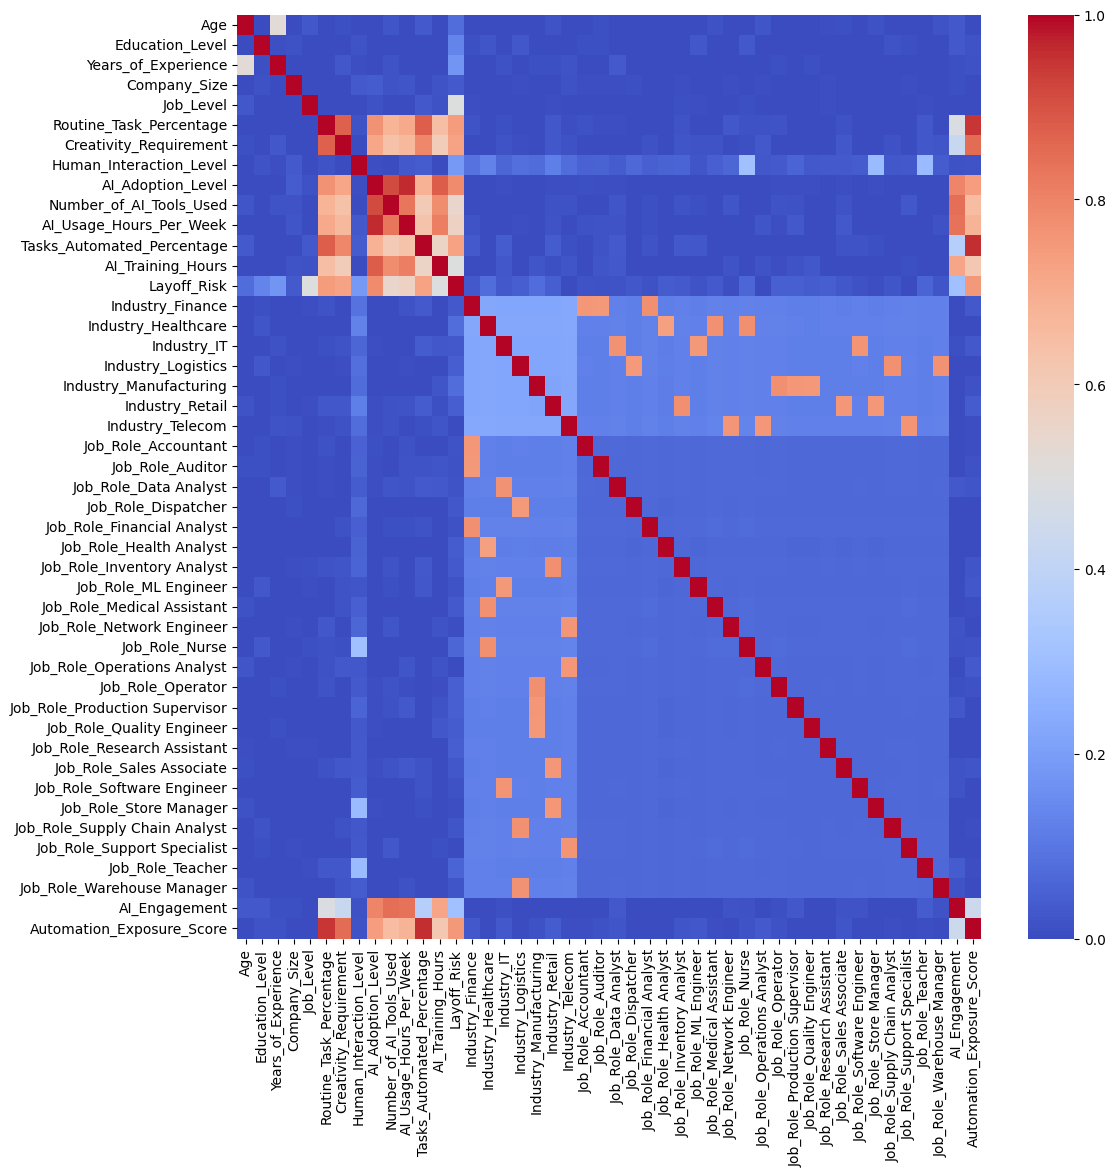

In [209]:
import phik
matrix = df.phik_matrix()
plt.figure(figsize=(12,12))
sns.heatmap(matrix, cmap='coolwarm');

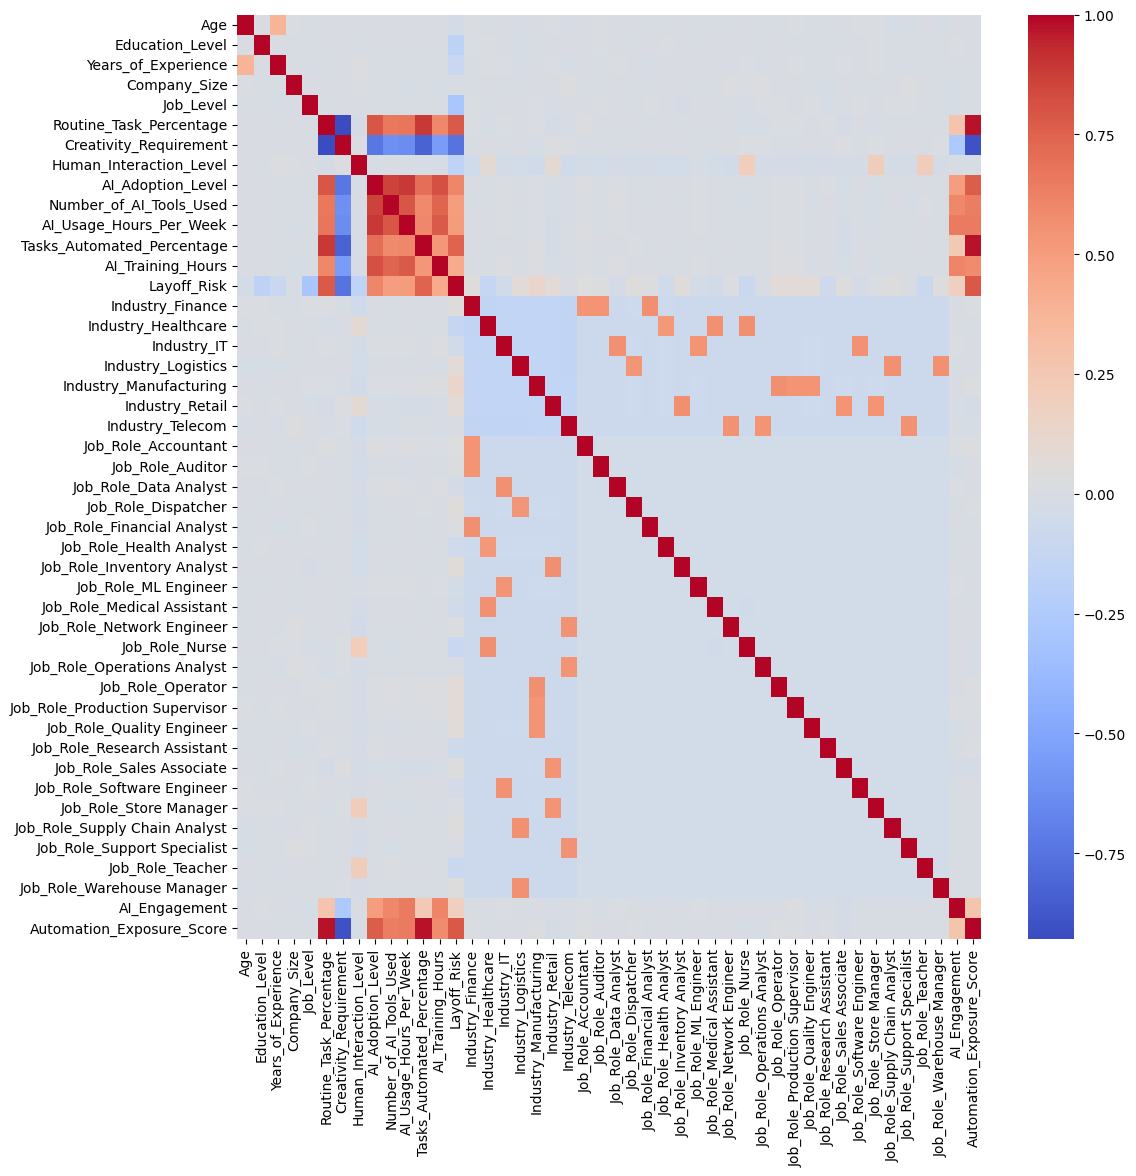

In [210]:
plt.figure(figsize=(12,12))
sns.heatmap(df.corr(), cmap='coolwarm');

# Кластеризация различными методами
На основен методов Kmeans, DBSCAN и AgglomerativeClustering будут собраны метрики silhouette_score, davies_bouldin_score, calinski_harabasz_score для дальнейшего определения качества модели и выбор лучшей из них. В каждом из методов будет подбор параметров для улучшения результатов.

In [211]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Kmeans

ЛУЧШАЯ МОДЕЛЬ DBSCAN:
Silhouette Score: 0.1832
Davies-Bouldin:e: 1.3510
Calinski-Harabasz: 8189.9466
Количество кластеров: 3


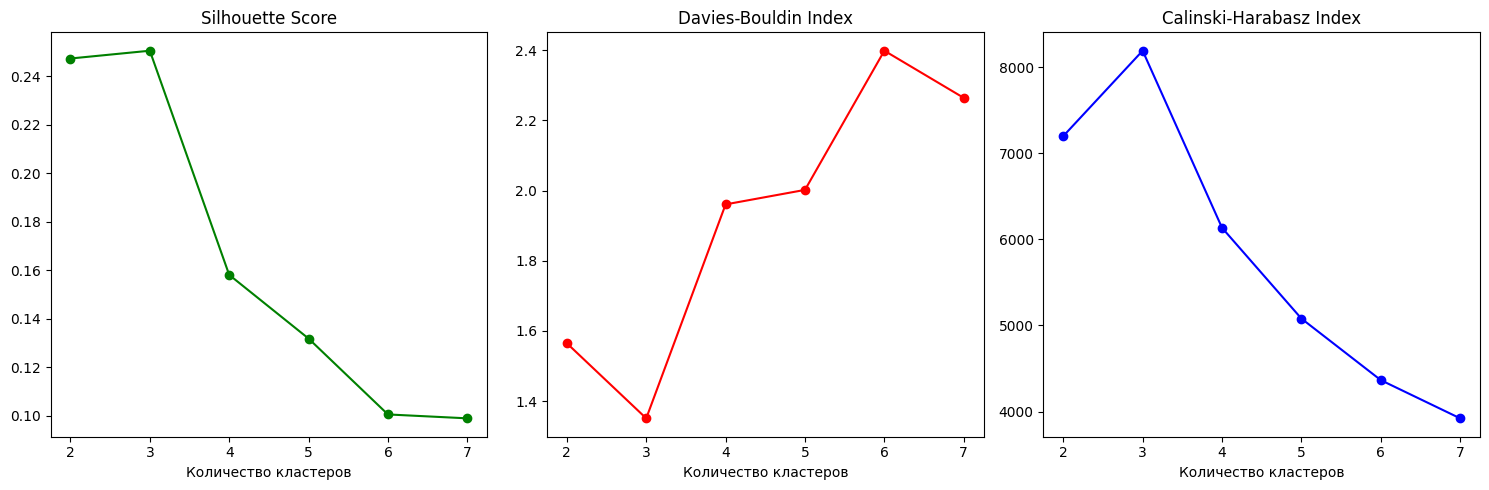

In [212]:
total_metric_kmeans = []
sill_curr = -10
for i in range(2,8):
    model = KMeans(n_clusters=i)
    labels = model.fit_predict(df)
    sill = silhouette_score(df, labels)
    if sill > sill_curr:
        sill_curr = sil
        best_labels_Kmeans = labels
        kmeans = [sill_curr, davies_bouldin_score(df, labels), calinski_harabasz_score(df, labels)]
    db = davies_bouldin_score(df, labels)
    ch = calinski_harabasz_score(df, labels)
    total_metric_kmeans.append([sill, db, ch])
    
total_metric_kmeans = np.array(total_metric_kmeans)
fig, axes = plt.subplots(ncols=3, nrows=1, figsize=(15, 5))

axes[0].plot(range(2, 8), total_metric_kmeans[:, 0], marker='o', color='green')
axes[0].set_title('Silhouette Score')
axes[0].set_xlabel('Количество кластеров')

axes[1].plot(range(2, 8), total_metric_kmeans[:, 1], marker='o', color='red')
axes[1].set_title('Davies-Bouldin Index')
axes[1].set_xlabel('Количество кластеров')

axes[2].plot(range(2, 8), total_metric_kmeans[:, 2], marker='o', color='blue')
axes[2].set_title('Calinski-Harabasz Index')
axes[2].set_xlabel('Количество кластеров')

plt.tight_layout()
print("ЛУЧШАЯ МОДЕЛЬ DBSCAN:")
print("=" * 50)
print(f"Silhouette Score: {kmeans[0]:.4f}")
print(f"Davies-Bouldin:e: {kmeans[1]:.4f}")
print(f"Calinski-Harabasz: {kmeans[2]:.4f}")
print(f"Количество кластеров: {len(set(best_labels_Kmeans))}")

# DBSCAN

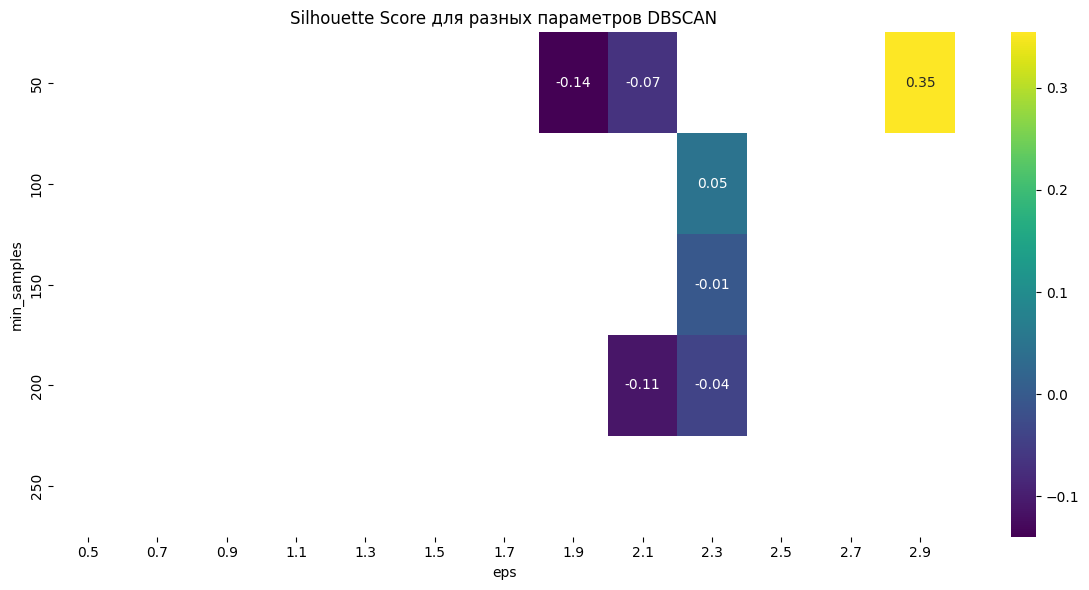

ЛУЧШАЯ МОДЕЛЬ DBSCAN:
eps: 2.8999999999999995
min_samples: 50
Silhouette Score: 0.3541
Количество кластеров: {np.int64(0), np.int64(1), np.int64(-1)}


In [213]:

eps_range = np.arange(0.5, 3, 0.2)
min_samples_range = [50, 100, 150, 200, 250]
sill_curr = -10

results = []
for ms in min_samples_range:
    row = []
    for eps in eps_range:
        model = DBSCAN(eps=eps, min_samples=ms)
        labels = model.fit_predict(df)
        if 2 < len(set(labels)) < 8:
            sill = silhouette_score(df, labels)
            if sill > sill_curr:
                sill_curr = sill
                best_model_params = {'n_samples': ms, 'eps': eps, 'clusters': set(labels)}
                best_labels_DBSCAN = labels
                dbscan = [sill_curr, davies_bouldin_score(df, labels), calinski_harabasz_score(df, labels)]
            row.append(sill)
        else:
            row.append(np.nan)
    results.append(row)

results = np.array(results)

plt.figure(figsize=(12, 6))
heatmap(results, xticklabels=eps_range.round(1), yticklabels=min_samples_range, 
        annot=True, cmap='viridis', fmt='.2f')
plt.xlabel('eps')
plt.ylabel('min_samples')
plt.title('Silhouette Score для разных параметров DBSCAN')
plt.tight_layout()
plt.show()

print("ЛУЧШАЯ МОДЕЛЬ DBSCAN:")
print("=" * 50)
print(f"eps: {best_model_params['eps']}")
print(f"min_samples: {best_model_params['n_samples']}")
print(f"Silhouette Score: {sill_curr:.4f}")
print(f"Количество кластеров: {best_model_params['clusters']}")
print("=" * 50)


# Agglomerative_Clustering

ЛУЧШАЯ МОДЕЛЬ AGGLOMERATIVE:
Метод линковки: ward
Количество кластеров: 2
Silhouette Score: 0.4849
Davies-Bouldin: 0.9221
Calinski-Harabasz: 7005.14


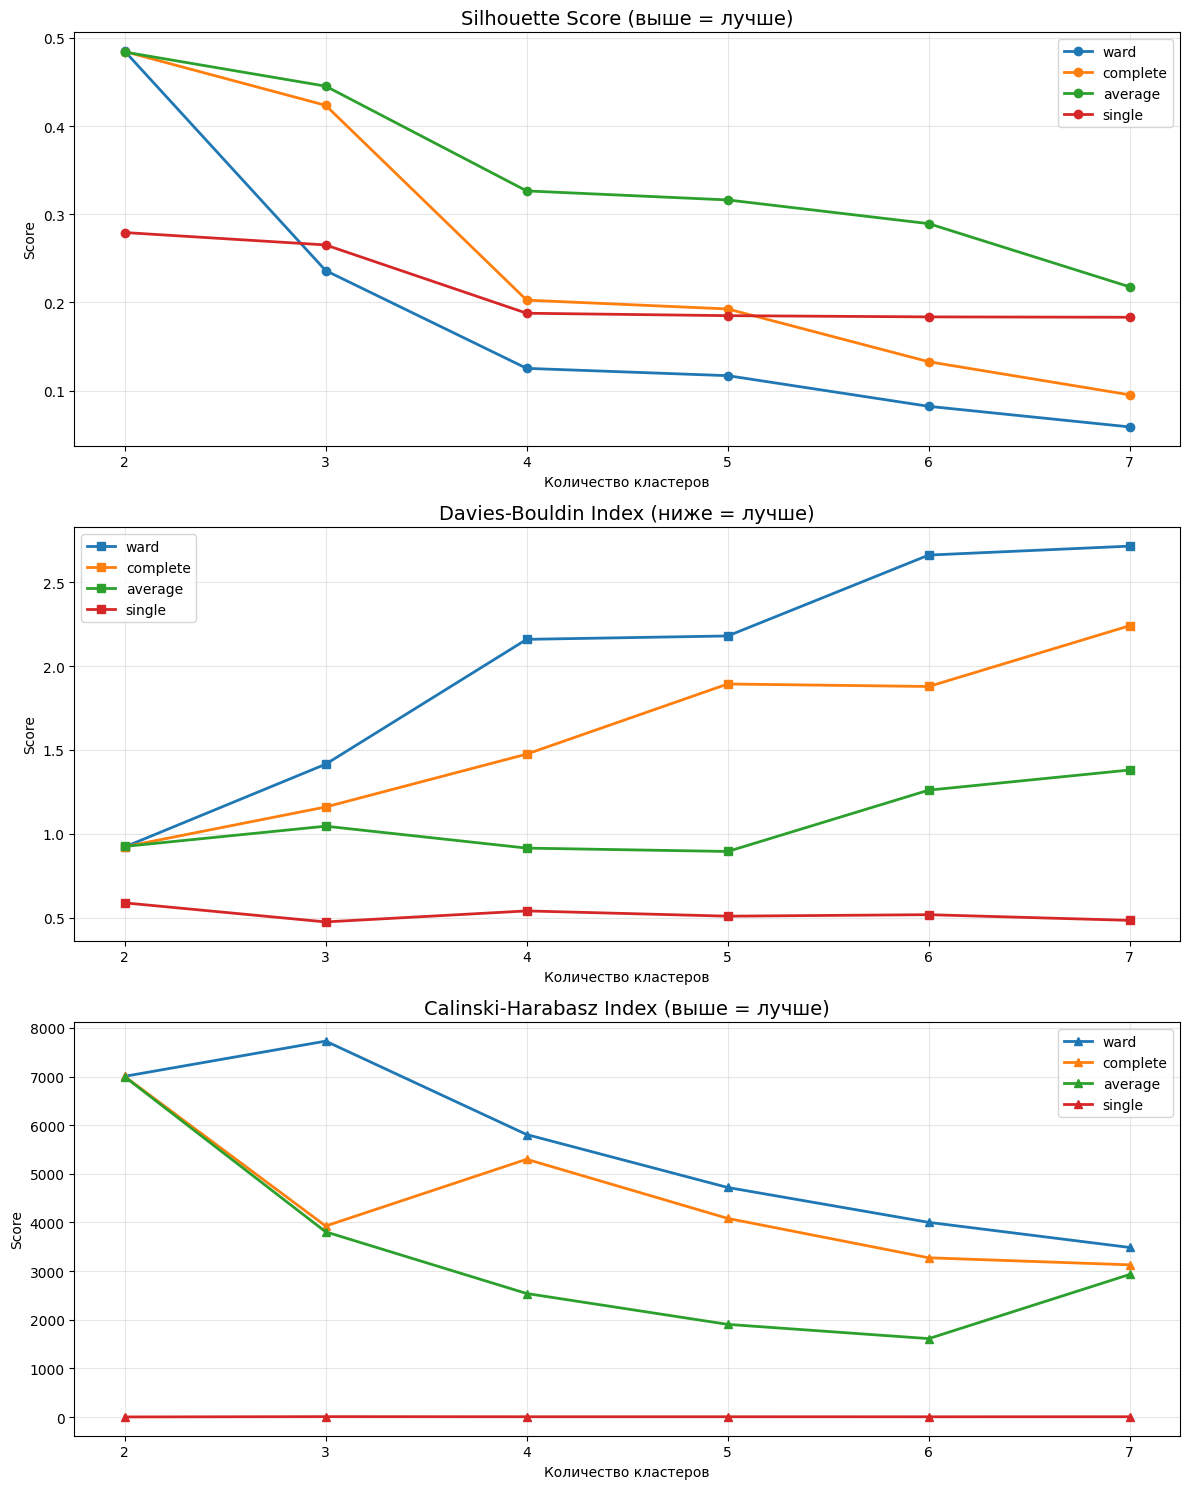

In [214]:

methods = ['ward', 'complete', 'average', 'single']
n_clusters_range = range(2, 8)

# Словарь для хранения результатов по каждому методу
results_by_method = {
    method: {'sil': [], 'db': [], 'ch': []} 
    for method in methods
}

# Перебираем методы и количество кластеров
for method in methods:
    for n in n_clusters_range:
        model = AgglomerativeClustering(n_clusters=n, linkage=method)
        labels = model.fit_predict(df)
        
        sil = silhouette_score(df, labels)
        db = davies_bouldin_score(df, labels)
        ch = calinski_harabasz_score(df, labels)
        
        results_by_method[method]['sil'].append(sil)
        results_by_method[method]['db'].append(db)
        results_by_method[method]['ch'].append(ch)

# Находим лучшую комбинацию
best_score = -1
best_params = None

for method in methods:
    for i, n in enumerate(n_clusters_range):
        sil = results_by_method[method]['sil'][i]
        if sil > best_score:
            best_score = sil
            best_params = {
                'method': method,
                'n_clusters': n,
                'silhouette': sil,
                'db': results_by_method[method]['db'][i],
                'ch': results_by_method[method]['ch'][i]
            }
            

print("=" * 50)
print("ЛУЧШАЯ МОДЕЛЬ AGGLOMERATIVE:")
print("=" * 50)
print(f"Метод линковки: {best_params['method']}")
print(f"Количество кластеров: {best_params['n_clusters']}")
print(f"Silhouette Score: {best_params['silhouette']:.4f}")
print(f"Davies-Bouldin: {best_params['db']:.4f}")
print(f"Calinski-Harabasz: {best_params['ch']:.2f}")
print("=" * 50)

# Визуализация
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

# График 1: Silhouette Score
for method in methods:
    axes[0].plot(list(n_clusters_range), results_by_method[method]['sil'], 
                 marker='o', label=method, linewidth=2)
axes[0].set_title('Silhouette Score (выше = лучше)', fontsize=14)
axes[0].set_xlabel('Количество кластеров')
axes[0].set_ylabel('Score')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# График 2: Davies-Bouldin Index
for method in methods:
    axes[1].plot(list(n_clusters_range), results_by_method[method]['db'], 
                 marker='s', label=method, linewidth=2)
axes[1].set_title('Davies-Bouldin Index (ниже = лучше)', fontsize=14)
axes[1].set_xlabel('Количество кластеров')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# График 3: Calinski-Harabasz Index
for method in methods:
    axes[2].plot(list(n_clusters_range), results_by_method[method]['ch'], 
                 marker='^', label=method, linewidth=2)
axes[2].set_title('Calinski-Harabasz Index (выше = лучше)', fontsize=14)
axes[2].set_xlabel('Количество кластеров')
axes[2].set_ylabel('Score')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Применяем лучшую модель
best_model = AgglomerativeClustering(
    n_clusters=best_params['n_clusters'], 
    linkage=best_params['method']
)
best_labels_Agglomerative = best_model.fit_predict(df)
agg = [best_params['silhouette'], best_params['db'], best_params['ch']]


## Визуализация кластеров в 2D-пространстве по ответам наших моделей

In [215]:

from sklearn.decomposition import PCA

def visulisation_2D(labels):
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(df)
    pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=df.index) 
    pca_df['cluster'] = labels
    plt.figure(figsize=(10, 8))
    sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='cluster', alpha=0.7)
    plt.title('Кластеры в пространстве PCA (2D)', fontsize=14)
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)')
    plt.legend(title='Кластер')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


--Kmeans--



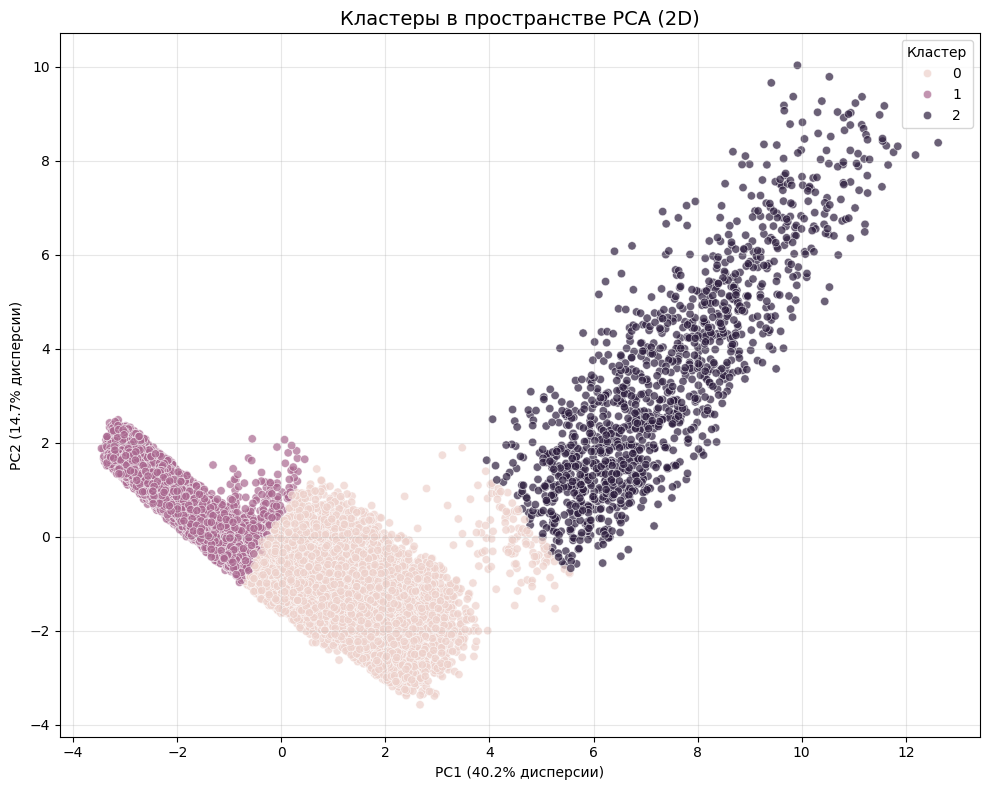

In [216]:
print('--Kmeans--')
print()
visulisation_2D(best_labels_Kmeans)

--DBSCAN--



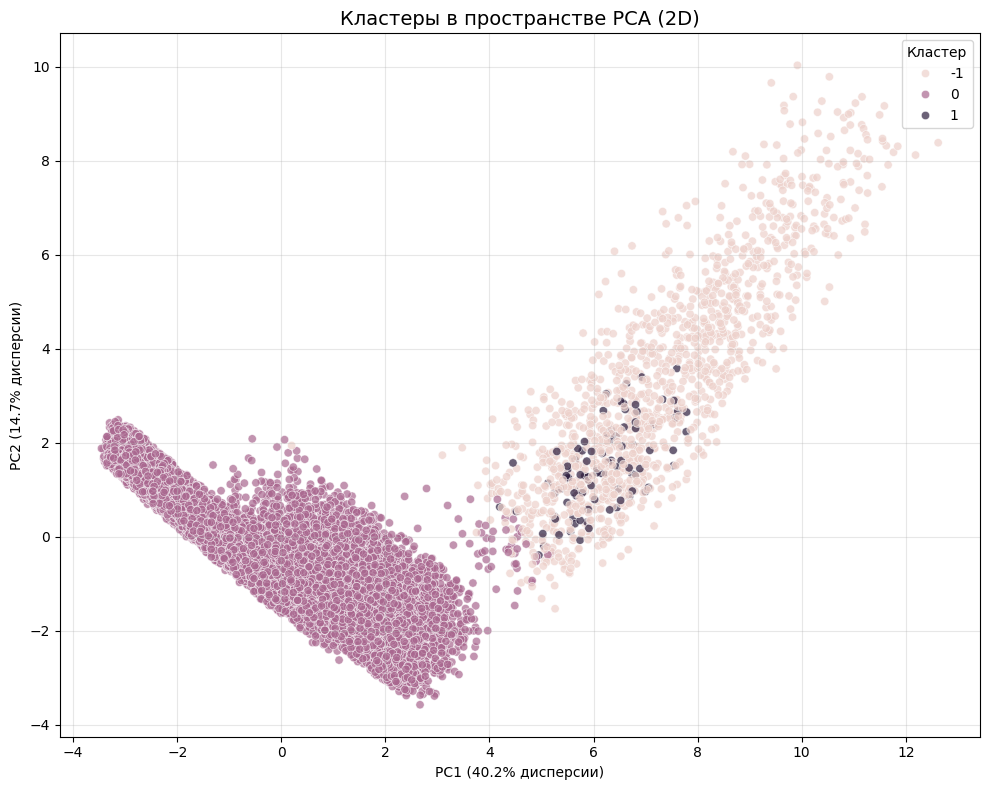

In [217]:
print('--DBSCAN--')
print()
visulisation_2D(best_labels_DBSCAN)

--Agglomerative_clustering--



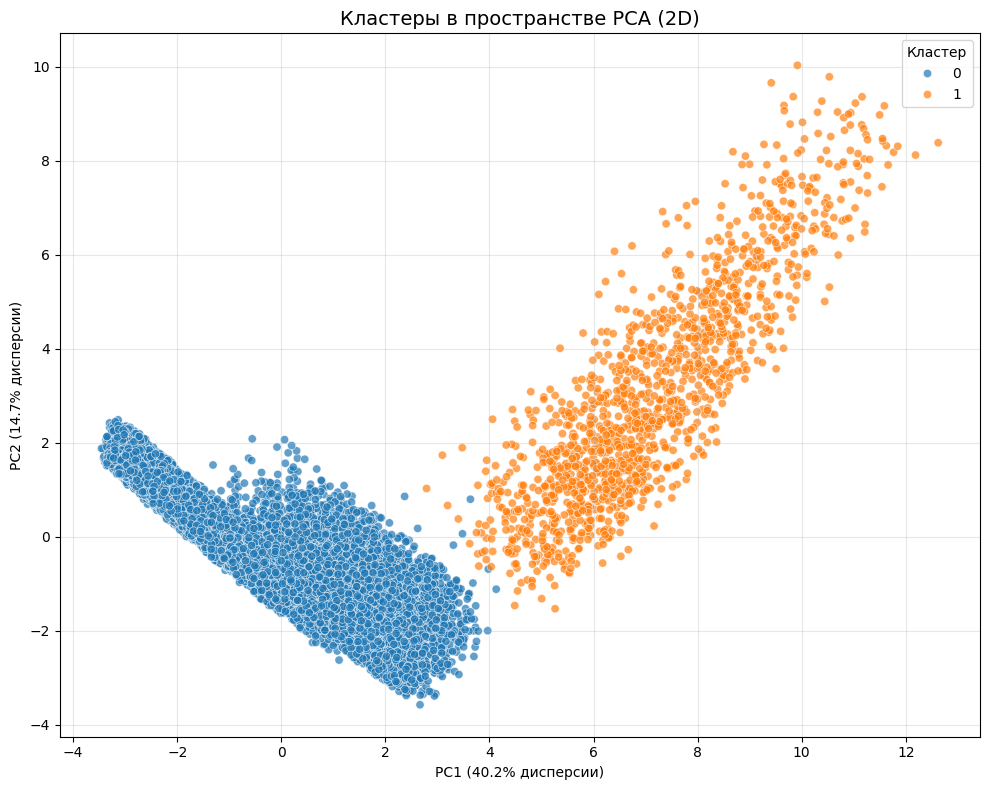

In [218]:
print('--Agglomerative_clustering--')
print()
visulisation_2D(best_labels_Agglomerative)


## Выбор лучшей модели

In [219]:
pd.DataFrame(data=[kmeans, dbscan, agg], index=['KMeans', 'DBSCAN', 'Agglomerative_Clustering'], columns=['Silhouette Score', 'Davies-Bouldin', 'Calinski-Harabasz'])

,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
KMeans,0.183197,1.351010,8189.946613
DBSCAN,0.354104,2.361881,3505.024817
Agglomerative_Clustering,0.484897,0.922107,7005.141373


In [220]:
nature_df = pd.read_csv('dataset.csv')
nature_df['AI_Engagement'] = nature_df['Number_of_AI_Tools_Used'] * nature_df['AI_Usage_Hours_Per_Week']
nature_df['Automation_Exposure_Score'] = (nature_df['Routine_Task_Percentage'] + nature_df['Tasks_Automated_Percentage']) / 2
nature_df['cluster'] = best_labels_Agglomerative

interval columns not set, guessing: ['Age', 'Years_of_Experience', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours', 'AI_Engagement', 'Automation_Exposure_Score', 'cluster']


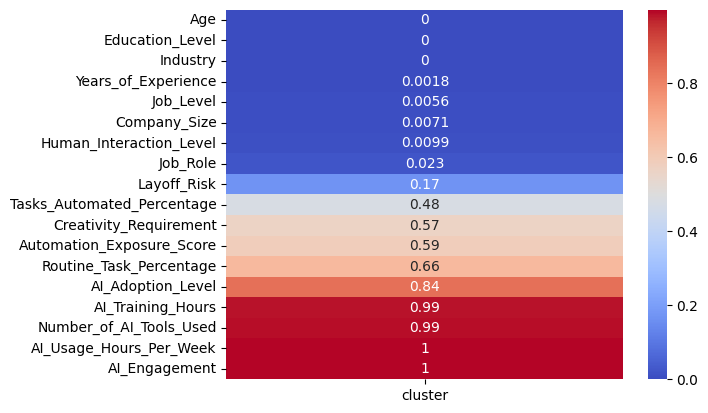

In [221]:
sns.heatmap(pd.DataFrame(nature_df.phik_matrix().loc['cluster'].sort_values().drop('cluster'), columns=['cluster']), cmap='coolwarm', annot=True);

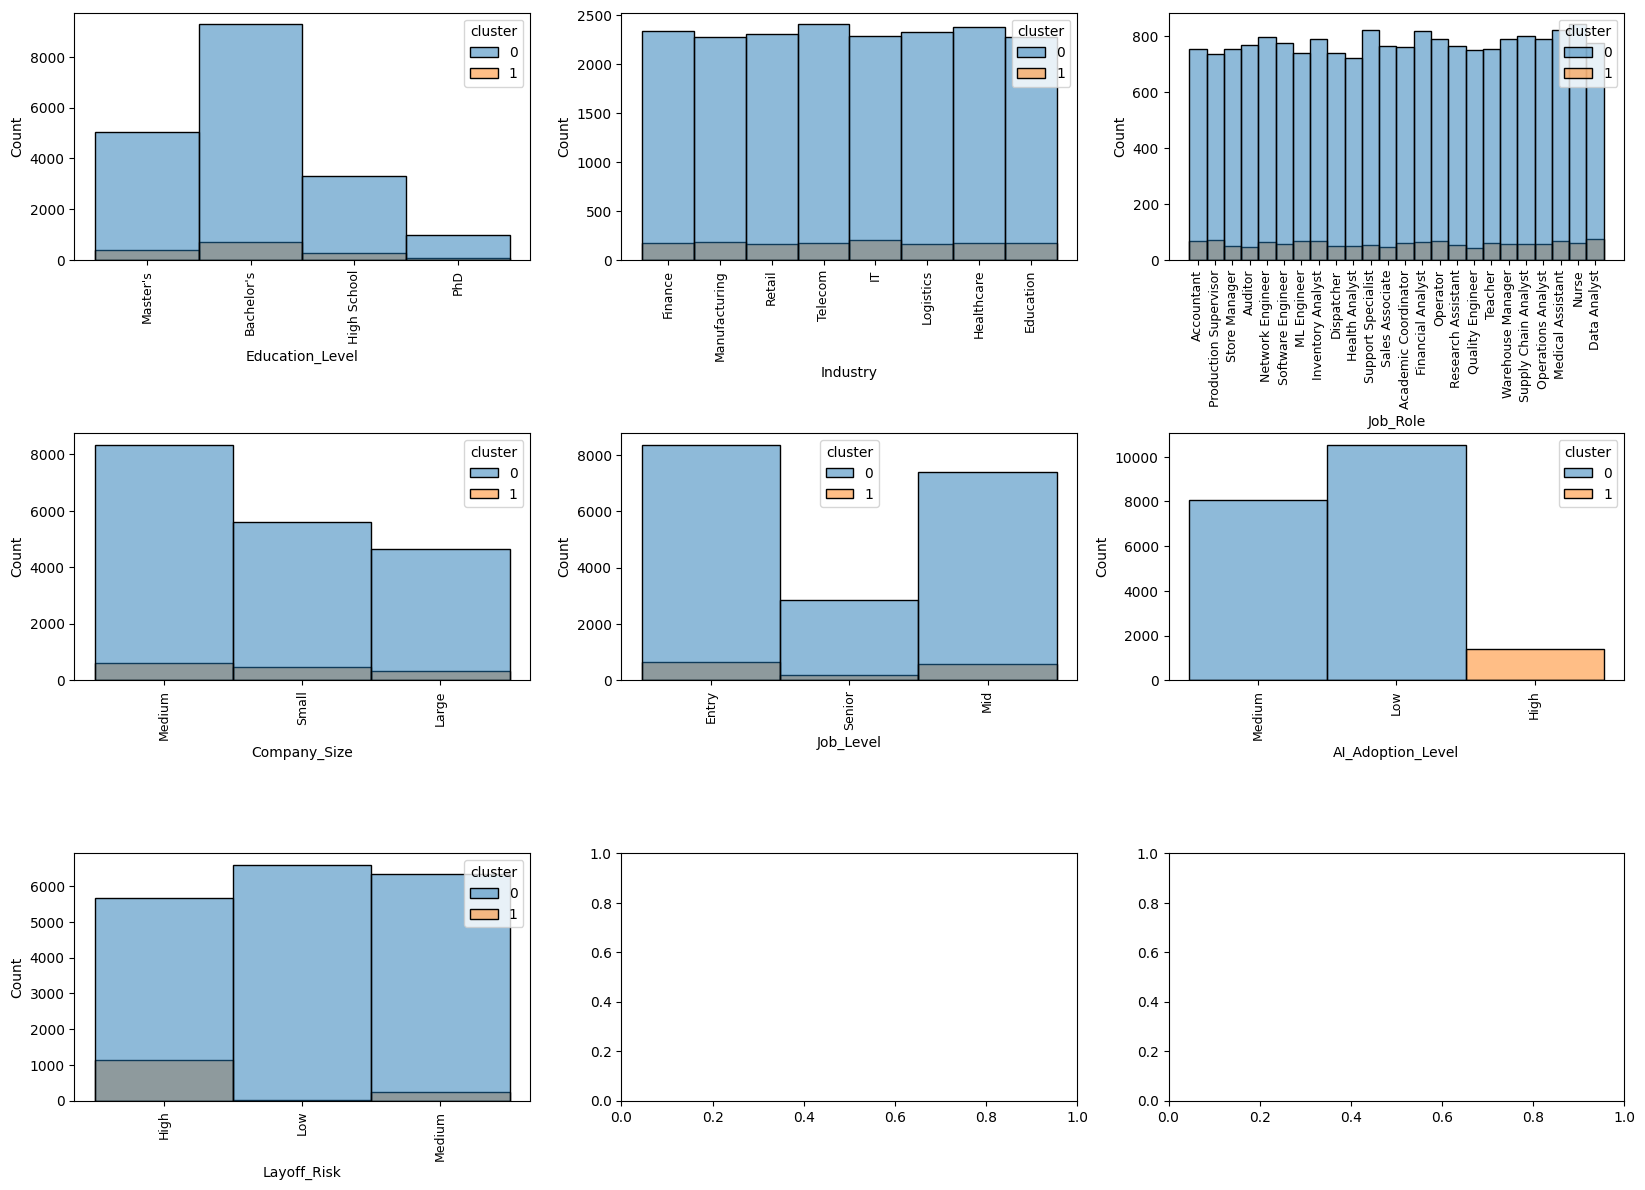

In [222]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 16))
i, j = 0, 0
for col in nature_df.select_dtypes('object').columns:
    if j > 2:
        j = 0 
        i += 1
    sns.histplot(nature_df, x=col, ax=axes[i,j], hue='cluster')
    axes[i,j].tick_params(axis='x', rotation=90, labelsize=9)
    j+=1
plt.subplots_adjust(hspace=0.7, bottom=0.2)


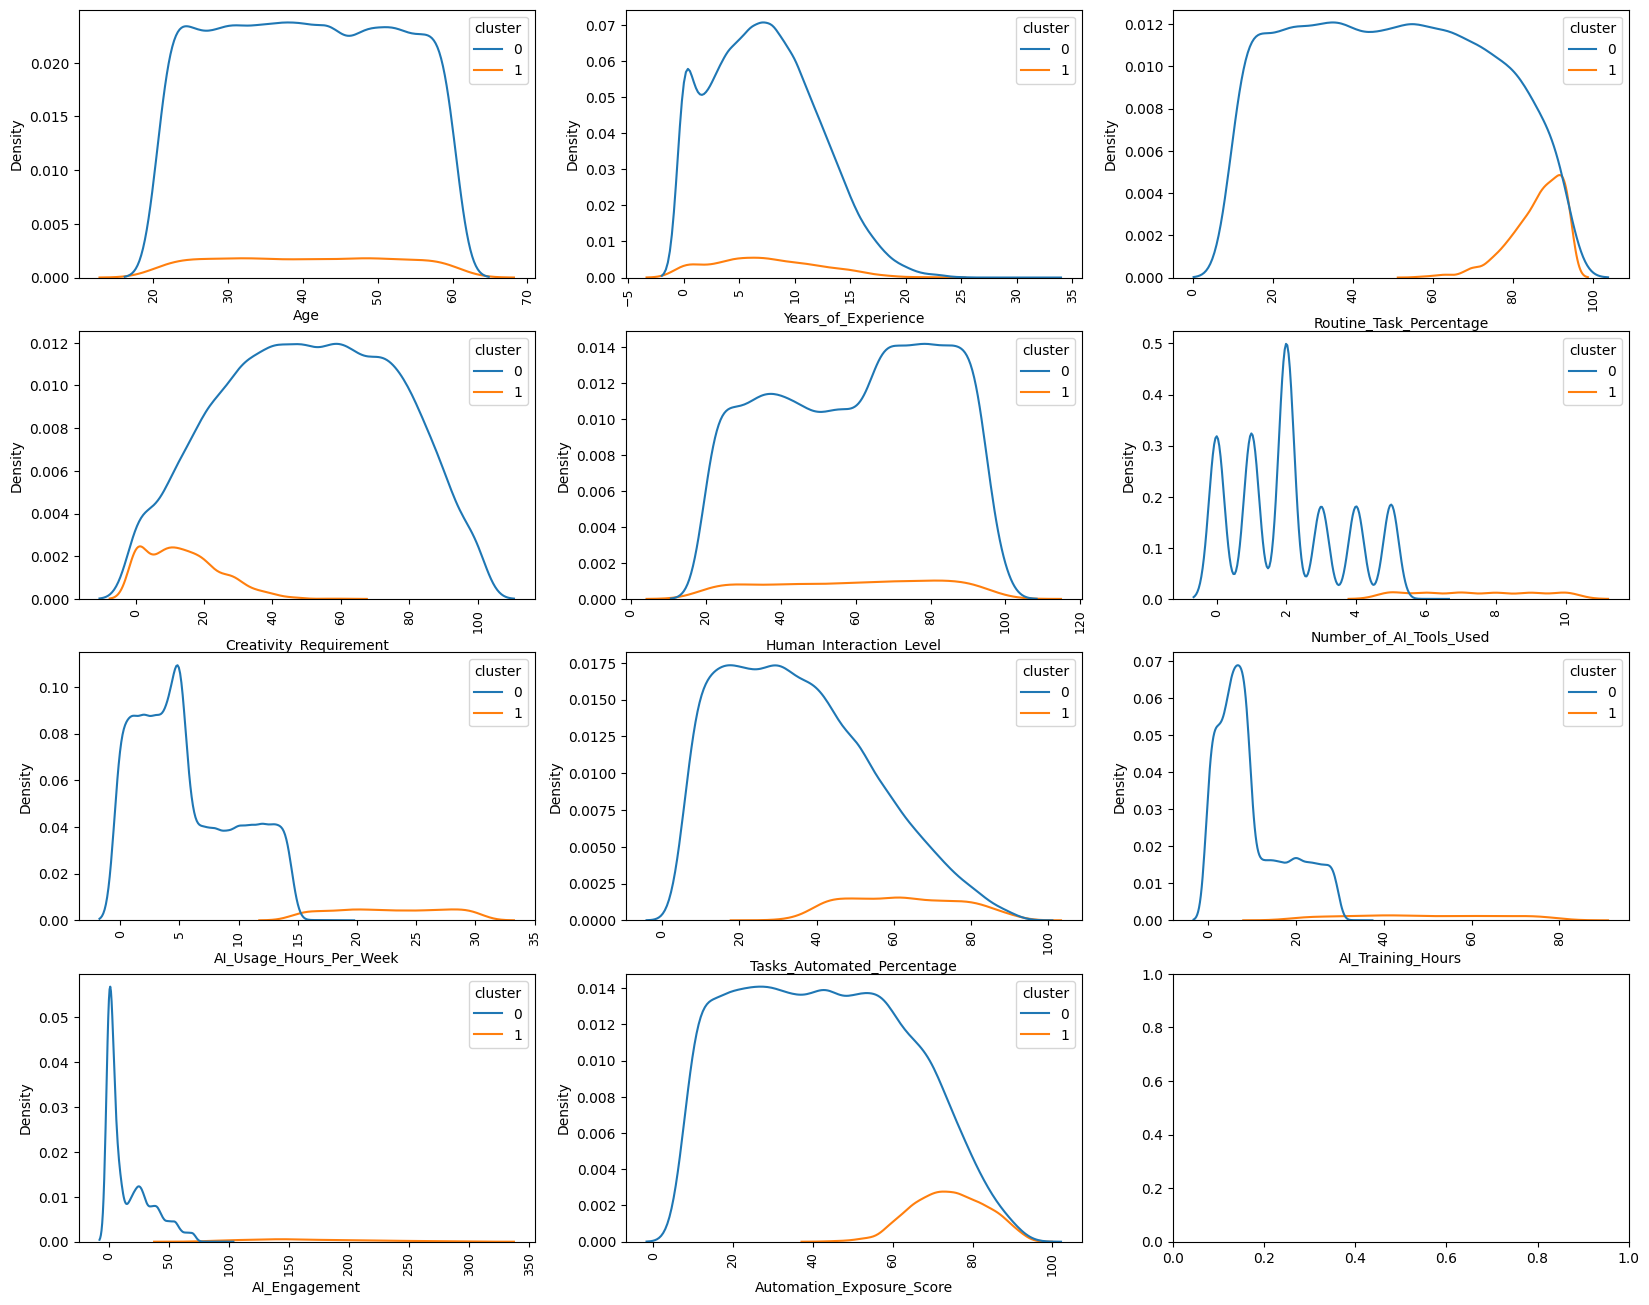

In [223]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(20, 16))
i, j = 0, 0
for col in nature_df.select_dtypes(['int64', 'float']).drop('cluster', axis=1).columns:
    if j > 2:
        j = 0 
        i += 1
    sns.kdeplot(nature_df, x=col, ax=axes[i,j], hue='cluster')
    axes[i,j].tick_params(axis='x', rotation=90, labelsize=9)
    j+=1


## Вывод

Исходя из графиков после кластеризации, можно сделать вывод что данные разделяются на 2 группы:
1) Сотрудники, глубоко погруженные в ИИ, максимально просторно использующее его в своей работе в соответстии со своими задачами, например на графике с Routine_task_percatage видно что у таких людей большая часть (>70%) задачи заключаются в автоматизации. Работа подразуемевает собой чисто прикладной характер и может быть востребована в любой отрасли, это видно по рисункам "Job Role" и "Industry" по разделению на класетры. Самое опасное для таких людей потерять свою креативность и уникальность в решения, по графику "Creativity_Requirment" и "Layoff_Risk" можно предположить что как раз таки взаимозаменяемость таких сотрудников представляет самую ближайшую опасность. Так же весомым фактором является уровень должности, Mid и Entry больше подвержены риску увольнения, ведь их задачи зачастую не представляю такой содержательной работы как у Senior. 
2) Сотрудники, менее погруженные в целом в задачи, связаннные с автоматизацией. Они тратят гораздо меньше времени на ИИ и опираются на свои уникальные знания и опыт. Преимущества таких сотрудников не скоро получится заменить, но с развитием ИИ модели приобретают новые веса и становятся точнее, тем более сущесвуеют системы RAG, которые зачастую узконаправлены. Так или иначе в большенстве профессий сущевстуют задачи, нуждающиеся в атоматизации. И для сотрудников с более творческой работой в том числе будет огромным преимущестом перед своими коллегами знание и умение использовать ИИ.